# **III. Câu hỏi Machine Learning**

### **3.1. Dự đoán ứng dụng đạt ngưỡng phổ biến đại chúng (Installs ≥ 1.000.000)**

**Người thực hiện:** *(điền tên thành viên)*

**Câu hỏi:** Chỉ dùng các thuộc tính mô tả sản phẩm và cấu hình kỹ thuật biết trước (không dùng `Reviews`, `Rating`), mô hình học máy phân loại được ứng dụng đạt `Installs` ≥ 1.000.000 tốt hơn baseline ngây thơ bao nhiêu, và đặc trưng nào đóng vai trò quyết định nhất?

**Động lực:** Giúp nhà phát triển độc lập và nhà phát hành ước lượng khả năng một ứng dụng đạt quy mô triệu lượt tải từ danh mục, thể loại, giá, dung lượng và phiên bản Android hỗ trợ, mà không bị đánh lừa bởi các chỉ số chỉ có sau khi ứng dụng đã có người dùng.

#### **1. Bài toán, nhãn và chống rò rỉ dữ liệu**

- **Bài toán:** phân loại nhị phân, `y = 1` nếu cận dưới `Installs` ≥ 1.000.000, ngược lại `y = 0`. Người dùng là nhà phát triển cần đánh giá trước khi hoặc ngay khi phát hành.
- **Đặc trưng dùng:** `Category`, `Genres`, `Content Rating`, `Price`, `Size_MB` kèm `Size_varies`, phiên bản Android tối thiểu (`Android_min`, `Android_varies`) và hai đặc trưng từ tên app (`Name_len`, `Name_words`).
- **Cột bị loại:** `Reviews` (Spearman 0,97 với `Installs`), `Rating` (chỉ có sau khi có người dùng), `Last Updated` và `Current Ver` (phát sinh sau phát hành), `Installs` (nhãn). `App` chỉ dùng làm khóa chia nhóm.
- **`Type` bị bỏ** vì Free khớp hoàn toàn với `Price` = 0 và Paid khớp hoàn toàn với `Price` > 0 (bảng bên dưới), giữ cả hai chỉ lặp thông tin.
- Dùng toàn bộ 10.357 dòng đã tiền xử lý (không loại bản ghi trùng tên), vì việc chia theo nhóm xử lý các dòng cùng tên.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data/raw").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.preprocessing as preprocessing

apps, _ = preprocessing.preprocess_apps(pd.read_csv(PROJECT_ROOT / "data/raw/googleplaystore.csv"))

# Nhãn: cận dưới Installs từ 1.000.000 trở lên.
apps["y"] = apps["Installs"].ge(1_000_000).astype(int)

print(f"Số dòng: {len(apps):,} | số tên ứng dụng: {apps['App'].nunique():,}")
print(f"Tỷ lệ lớp 1 (Installs ≥ 1M): {apps['y'].mean():.3f}")
conflict = apps.groupby("App")["y"].nunique().gt(1).sum()
print(f"Tên ứng dụng có nhãn mâu thuẫn giữa các dòng: {conflict}")
print(pd.crosstab(apps["Type"], apps["Price"].gt(0), rownames=["Type"], colnames=["Price > 0"]))

Số dòng: 10,357 | số tên ứng dụng: 9,659
Tỷ lệ lớp 1 (Installs ≥ 1M): 0.391
Tên ứng dụng có nhãn mâu thuẫn giữa các dòng: 6
Price > 0  False  True 
Type                   
Free        9592      0
Paid           0    765


Tỷ lệ lớp 1 là 39,1%, không quá lệch nhưng baseline đoán lớp đa số vẫn đạt Accuracy 0,61 mà không phân loại được ứng dụng phổ biến nào. Có 6 tên ứng dụng có nhãn khác nhau giữa các dòng, rất ít nên không ảnh hưởng đáng kể.

In [2]:
# Đặc trưng chỉ gồm thông tin mô tả sản phẩm và cấu hình kỹ thuật.
ver = apps["Android Ver"].astype("string")
X = pd.DataFrame({
    "Category": apps["Category"].astype(str),
    "Genres": apps["Genres"].astype(str),
    "Content Rating": apps["Content Rating"].astype(str),
    "Price": apps["Price"],
    "Size_MB": apps["Size_MB"],
    "Size_varies": apps["Size_varies"].astype(float),
    # Phiên bản Android tối thiểu; "Varies with device" không có số nên để NaN và có cờ riêng.
    "Android_min": ver.str.extract(r"^(\d+(?:\.\d+)?)")[0].astype(float),
    "Android_varies": ver.eq("Varies with device").astype(float),
    "Name_len": apps["App"].str.len(),
    "Name_words": apps["App"].str.split().str.len(),
})
y, groups = apps["y"], apps["App"]

CAT_COLS = ["Category", "Genres", "Content Rating"]
NUM_COLS = [c for c in X.columns if c not in CAT_COLS]
TECH_COLS = ["Size_MB", "Size_varies", "Android_min", "Android_varies", "Name_len", "Name_words"]

print("Cột bị loại để tránh rò rỉ: Reviews, Rating, Installs (nhãn), Last Updated, Current Ver, App (chỉ dùng làm nhóm)")
print("Cột Type bị bỏ vì trùng thông tin với Price > 0 (xem bảng trên).")
display(X.isna().sum().rename("Thiếu").to_frame().T)

Cột bị loại để tránh rò rỉ: Reviews, Rating, Installs (nhãn), Last Updated, Current Ver, App (chỉ dùng làm nhóm)
Cột Type bị bỏ vì trùng thông tin với Price > 0 (xem bảng trên).


,Category,Genres,Content Rating,Price,Size_MB,Size_varies,Android_min,Android_varies,Name_len,Name_words
Thiếu,0,0,0,0,1526,0,1223,2,0,0


`Size_MB` có 1.526 giá trị thiếu, đều là nhóm "Varies with device"; `Android_min` có 1.223 giá trị thiếu do "Varies with device" hoặc thiếu phiên bản. Hai nhóm này được điền trung vị trong Pipeline (chỉ học trên train) và đã có cờ `Size_varies`, `Android_varies` đi kèm.

#### **2. Chia dữ liệu theo nhóm**

Nhiều dòng cùng một tên ứng dụng thuộc cùng một thực thể, nên nhóm dùng `GroupShuffleSplit` (80% train, 20% test) với nhóm là `App`. Tập test chỉ dùng để đánh giá cuối cùng.

In [3]:
from sklearn.model_selection import GroupShuffleSplit

# Chia theo nhóm App: các dòng cùng tên luôn nằm cùng một phía.
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

print(f"Train: {len(X_train):,} dòng, {g_train.nunique():,} app | Test: {len(X_test):,} dòng, {groups.iloc[test_idx].nunique():,} app")
print("Giao nhau về tên app giữa train và test:", len(set(g_train) & set(groups.iloc[test_idx])))
print(f"Tỷ lệ lớp 1: train {y_train.mean():.3f} | test {y_test.mean():.3f}")

Train: 8,291 dòng, 7,727 app | Test: 2,066 dòng, 1,932 app
Giao nhau về tên app giữa train và test: 0
Tỷ lệ lớp 1: train 0.392 | test 0.388


Hai tập không có tên ứng dụng nào chung và tỷ lệ lớp tương đương nhau (0,392 và 0,388).

#### **3. Pipeline, so sánh mô hình và tinh chỉnh**

Mọi bước tiền xử lý nằm trong `Pipeline`: cột số dùng `SimpleImputer(median)` và `StandardScaler`, cột phân loại dùng `OneHotEncoder(min_frequency=20, handle_unknown="ignore")` để gộp thể loại hiếm (`Genres` có 119 giá trị, 57 giá trị dưới 10 dòng). Ba mô hình được so sánh:

1. **Baseline:** `DummyClassifier(strategy="most_frequent")`.
2. **Logistic Regression:** mô hình tuyến tính có điều chuẩn, tinh chỉnh `C`.
3. **HistGradientBoosting:** mô hình phi tuyến, tinh chỉnh `learning_rate`, `max_depth`, `min_samples_leaf`.

Tinh chỉnh bằng `GridSearchCV` với `GroupKFold(5)` theo `App`, chỉ trên tập train, chấm điểm bằng ROC-AUC.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_pipe(model, num_cols, cat_cols):
    parts = [("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols)]
    if cat_cols:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), cat_cols))
    return Pipeline([("prep", ColumnTransformer(parts)), ("model", model)])

cv = GroupKFold(n_splits=5)
searches = {
    "Dummy (most_frequent)": make_pipe(DummyClassifier(strategy="most_frequent"), NUM_COLS, CAT_COLS),
    "Logistic Regression": GridSearchCV(
        make_pipe(LogisticRegression(max_iter=2000), NUM_COLS, CAT_COLS),
        {"model__C": [0.01, 0.1, 1, 10]}, cv=cv, scoring="roc_auc"),
    "HistGradientBoosting": GridSearchCV(
        make_pipe(HistGradientBoostingClassifier(random_state=42), NUM_COLS, CAT_COLS),
        {"model__learning_rate": [0.03, 0.1], "model__max_depth": [3, None], "model__min_samples_leaf": [20, 50]},
        cv=cv, scoring="roc_auc"),
}

# Chỉ fit và CV trên tập train.
from sklearn.model_selection import cross_val_score
cv_rows = []
for name, est in searches.items():
    if isinstance(est, GridSearchCV):
        est.fit(X_train, y_train, groups=g_train)
        cv_rows.append({"Mô hình": name, "ROC-AUC CV (train)": est.best_score_, "Siêu tham số tốt nhất": est.best_params_})
    else:
        est.fit(X_train, y_train)
        s = cross_val_score(est, X_train, y_train, groups=g_train, cv=cv, scoring="roc_auc")
        cv_rows.append({"Mô hình": name, "ROC-AUC CV (train)": s.mean(), "Siêu tham số tốt nhất": "-"})
with pd.option_context("display.max_colwidth", None, "display.width", 200):
    display(pd.DataFrame(cv_rows).round(4))

,Mô hình,ROC-AUC CV (train),Siêu tham số tốt nhất
0,Dummy (most_frequent),0.5000,-
1,Logistic Regression,0.8351,{'model__C': 10}
2,HistGradientBoosting,0.8536,"{'model__learning_rate': 0.1, 'model__max_depth': None, 'model__min_samples_leaf': 20}"


Hai mô hình đều vượt baseline (ROC-AUC 0,50) rõ rệt khi kiểm định chéo theo nhóm: Logistic Regression 0,835 và HistGradientBoosting 0,854.

#### **4. Đánh giá trên tập test**

Nhóm báo cáo ROC-AUC (không phụ thuộc ngưỡng), PR-AUC và F1 (nhấn vào lớp phổ biến). Accuracy chỉ để đối chiếu: baseline đạt 0,61 nhưng F1 bằng 0 vì không bao giờ dự đoán lớp 1, nên Accuracy một mình dễ gây hiểu lầm khi lớp 0 chiếm đa số.

In [5]:
from sklearn.metrics import accuracy_score, average_precision_score, f1_score, roc_auc_score

# Đánh giá tập test đúng một lần cho từng mô hình đã chọn.
proba, pred, rows = {}, {}, []
for name, est in searches.items():
    p = est.predict_proba(X_test)[:, 1]
    proba[name], pred[name] = p, (p >= 0.5).astype(int)
    rows.append({"Mô hình": name,
                 "ROC-AUC": roc_auc_score(y_test, p),
                 "PR-AUC": average_precision_score(y_test, p),
                 "F1": f1_score(y_test, pred[name]),
                 "Accuracy": accuracy_score(y_test, pred[name])})
test_scores = pd.DataFrame(rows).set_index("Mô hình")
display(test_scores.round(4))
print(f"Tỷ lệ lớp 1 ở test (PR-AUC của baseline ngẫu nhiên): {y_test.mean():.3f}")

,ROC-AUC,PR-AUC,F1,Accuracy
Mô hình,,,,
Dummy (most_frequent),0.5000,0.3877,0.0000,0.6123
Logistic Regression,0.8428,0.7692,0.6713,0.7720
HistGradientBoosting,0.8584,0.7919,0.7165,0.7909


Tỷ lệ lớp 1 ở test (PR-AUC của baseline ngẫu nhiên): 0.388


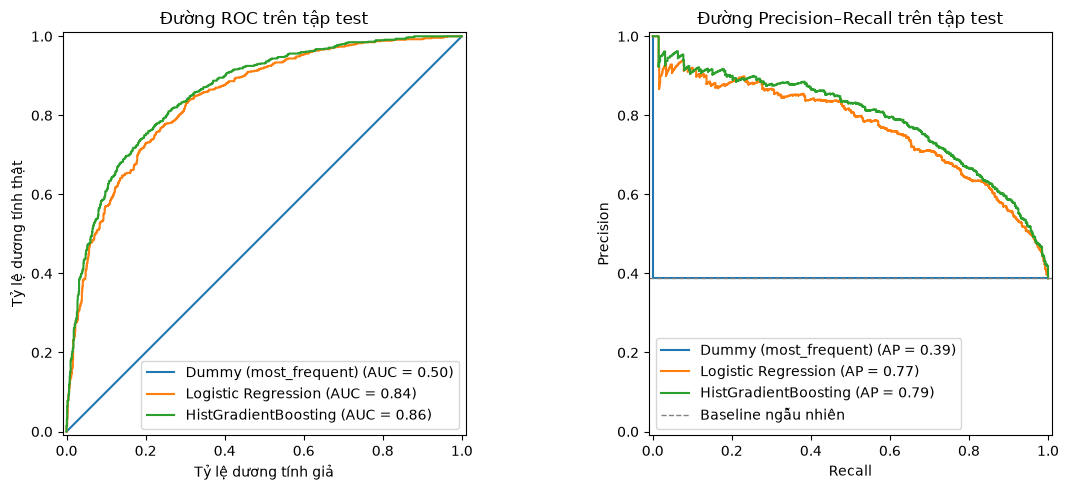

In [6]:
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name in proba:
    RocCurveDisplay.from_predictions(y_test, proba[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba[name], name=name, ax=axes[1])
axes[0].set(title="Đường ROC trên tập test", xlabel="Tỷ lệ dương tính giả", ylabel="Tỷ lệ dương tính thật")
axes[1].set(title="Đường Precision–Recall trên tập test", xlabel="Recall", ylabel="Precision")
axes[1].axhline(y_test.mean(), color="gray", ls="--", lw=1, label="Baseline ngẫu nhiên")
axes[1].legend()
plt.tight_layout()
plt.show()

- HistGradientBoosting đạt ROC-AUC **0,858**, PR-AUC **0,792**, F1 **0,717**; Logistic Regression đạt 0,843, 0,769 và 0,671. Baseline có ROC-AUC 0,500, PR-AUC 0,388 và F1 0.
- So với baseline, HistGradientBoosting tăng ROC-AUC thêm **0,358**, PR-AUC thêm **0,404** (gấp khoảng 2 lần mức ngẫu nhiên 0,388) và F1 thêm 0,717.
- Mô hình phi tuyến hơn Logistic Regression khoảng 0,015 ROC-AUC, nên phần lớn tín hiệu đã có tính tuyến tính theo đặc trưng, mô hình phi tuyến chỉ cải thiện thêm một ít.

#### **5. Phân tích lỗi**

Nhóm lấy mô hình tốt nhất, xem ma trận nhầm lẫn, tỷ lệ dương tính giả (FP rate, tính trên các app thật sự < 1M) và âm tính giả (FN rate, tính trên các app thật sự ≥ 1M) theo nhóm kích thước và `Category` (chỉ các danh mục có từ 40 dòng test), rồi liệt kê các app sai nặng nhất.

In [7]:
from sklearn.metrics import confusion_matrix

best_name = test_scores["ROC-AUC"].iloc[1:].idxmax()
err = apps.loc[X_test.index, ["App", "Category", "Size_MB", "Size_varies", "Price", "Installs"]].copy()
err["y"], err["proba"] = y_test.values, proba[best_name]
err["pred"] = (err["proba"] >= 0.5).astype(int)
err["FP"] = err["pred"].eq(1) & err["y"].eq(0)
err["FN"] = err["pred"].eq(0) & err["y"].eq(1)
err["Size_group"] = pd.cut(err["Size_MB"], [0, 5, 20, 50, np.inf], labels=["<5MB", "5–20MB", "20–50MB", "≥50MB"])
err["Size_group"] = err["Size_group"].cat.add_categories("Varies").fillna("Varies")

print(f"Mô hình tốt nhất: {best_name}")
tn, fp, fn, tp = confusion_matrix(y_test, err["pred"]).ravel()
display(pd.DataFrame([[tn, fp], [fn, tp]], index=["Thực tế 0", "Thực tế 1"], columns=["Dự đoán 0", "Dự đoán 1"]))

def error_rates(col, min_n):
    t = err.groupby(col, observed=True).agg(n=("y", "size"), FP_count=("FP", "sum"), FN_count=("FN", "sum"),
                                              n_neg=("y", lambda s: s.eq(0).sum()), n_pos=("y", "sum"))
    t["FP rate"] = t["FP_count"] / t["n_neg"]
    t["FN rate"] = t["FN_count"] / t["n_pos"]
    return t[t["n"] >= min_n][["n", "FP rate", "FN rate"]].round(3)

display(error_rates("Size_group", 1))
display(error_rates("Category", 40).sort_values("n", ascending=False))

Mô hình tốt nhất: HistGradientBoosting


,Dự đoán 0,Dự đoán 1
Thực tế 0,1088,177
Thực tế 1,255,546


,n,FP rate,FN rate
Size_group,,,
<5MB,476,0.010,0.910
5–20MB,624,0.104,0.624
20–50MB,459,0.202,0.342
≥50MB,226,0.426,0.101
Varies,281,0.677,0.037


,n,FP rate,FN rate
Category,,,
FAMILY,409,0.128,0.336
GAME,228,0.380,0.094
TOOLS,181,0.066,0.339
BUSINESS,94,0.024,0.333
MEDICAL,86,0.000,1.000
SPORTS,83,0.067,0.526
PRODUCTIVITY,78,0.103,0.436
FINANCE,71,0.122,0.364
LIFESTYLE,70,0.115,0.556


- Ở ngưỡng 0,5, mô hình bỏ sót 255 app phổ biến (FN) và gán nhầm 177 app chưa phổ biến (FP).
- **Theo kích thước:** lỗi phụ thuộc mạnh vào `Size`. App <5MB bị bỏ sót 91% (FN rate 0,910) còn FP gần như 0. App "Varies with device" có FP rate 0,677 và FN rate chỉ 0,037. Nghĩa là mô hình đang coi dung lượng lớn hoặc không xác định là dấu hiệu phổ biến, nhóm nhỏ gần như bị mặc định là không phổ biến.
- **Theo danh mục:** `GAME` (FP 0,380) và `SHOPPING` (0,381) bị dự đoán thừa, `COMMUNICATION` và `PHOTOGRAPHY` cũng cao (khoảng 0,28). `MEDICAL` có FN rate 1,000 (mọi app phổ biến đều bị bỏ sót, chỉ vài app), `PERSONALIZATION` 0,632, `BOOKS_AND_REFERENCE` 0,636.

In [8]:
cols = ["App", "Category", "Size_MB", "Price", "Installs", "proba"]
print("10 app Installs < 1M nhưng bị dự đoán xác suất cao nhất (FP nặng):")
display(err[err["y"].eq(0)].nlargest(10, "proba")[cols].round(3))
print("10 app Installs ≥ 1M nhưng bị dự đoán xác suất thấp nhất (FN nặng):")
display(err[err["y"].eq(1)].nsmallest(10, "proba")[cols].round(3))

10 app Installs < 1M nhưng bị dự đoán xác suất cao nhất (FP nặng):


,App,Category,Size_MB,Price,Installs,proba
825,Universal Kids,ENTERTAINMENT,21.0,0.0,500000,0.956
9563,Ex Explorer : Dual view exproler / file manager,TOOLS,NaN,0.0,50000,0.949
790,Harkins Theatres,ENTERTAINMENT,12.0,0.0,100000,0.931
7650,SuperBikers 2,GAME,NaN,0.0,500000,0.921
2645,"Hole19: Golf GPS App, Rangefinder & Scorecard",SPORTS,NaN,0.0,100000,0.920
822,CW Seed,ENTERTAINMENT,13.0,0.0,500000,0.919
3421,"Dynavix - Navigation, Maps, Traffic data & Cam...",MAPS_AND_NAVIGATION,NaN,0.0,50000,0.911
8458,DV-4036 by Somikon,PHOTOGRAPHY,44.0,0.0,1000,0.909
1843,Fruit Cube Blast,FAMILY,80.0,0.0,500000,0.903
803,Acorn TV: World-class TV from Britain and Beyond,ENTERTAINMENT,23.0,0.0,50000,0.898


10 app Installs ≥ 1M nhưng bị dự đoán xác suất thấp nhất (FN nặng):


,App,Category,Size_MB,Price,Installs,proba
1391,H Pack,LIFESTYLE,1.7,0.00,1000000,0.022
861,Fever,EVENTS,12.0,0.00,1000000,0.024
4876,Ayat - Al Quran,FAMILY,8.5,0.00,5000000,0.026
1983,Minecraft,FAMILY,NaN,6.99,10000000,0.027
3893,Minecraft,FAMILY,NaN,6.99,10000000,0.027
2988,HD Widgets,PERSONALIZATION,26.0,0.99,1000000,0.034
6452,HD Widgets,PERSONALIZATION,26.0,0.99,1000000,0.034
5034,True Skate,SPORTS,73.0,1.99,1000000,0.041
8670,Lost Journey (Dreamsky),GAME,29.0,0.99,1000000,0.045
4873,Al Quran Audio (Full 30 Juz),FAMILY,3.6,0.00,1000000,0.045


- **FP nặng:** nhiều app giải trí hoặc thuộc thương hiệu (`Universal Kids`, `Harkins Theatres`, `CW Seed`, `Acorn TV`) có đặc trưng giống app lớn (miễn phí, danh mục giải trí, dung lượng vừa) nhưng chỉ có 50K–500K lượt cài. Một số có `Size_MB` thiếu (Varies) nên bị mô hình coi như app lớn.
- **FN nặng:** các app nhỏ hoặc có trả phí nhưng cực phổ biến, ví dụ `Minecraft` (6,99 USD, 10 triệu), `HD Widgets` (0,99 USD), `True Skate` (1,99 USD), và các app Hồi giáo nhẹ (`Ayat - Al Quran`, `Al Quran Audio`) dung lượng dưới 9MB. Phổ biến của chúng đến từ thương hiệu hoặc nhu cầu cộng đồng, không có trong các đặc trưng mô tả sản phẩm.

#### **6. Giải thích mô hình bằng permutation importance**

Nhóm xáo trộn từng cột gốc trong tập test (20 lần) rồi đo mức giảm ROC-AUC của toàn Pipeline, nên các cột one-hot của `Category` hoặc `Genres` được tính chung thành một đặc trưng. Ngoài ra, nhóm huấn luyện một mô hình chỉ dùng đặc trưng kỹ thuật, với cùng siêu tham số, để biết đóng góp của chúng khi không có thông tin danh mục và giá.

,mean,std
Category,0.0826,0.0061
Size_MB,0.0793,0.0049
Price,0.0592,0.0073
Name_len,0.0407,0.0047
Genres,0.0250,0.0029
Size_varies,0.0212,0.0032
Name_words,0.0148,0.0021
Android_varies,0.0085,0.0018
Android_min,0.0055,0.0019
Content Rating,0.0033,0.0011


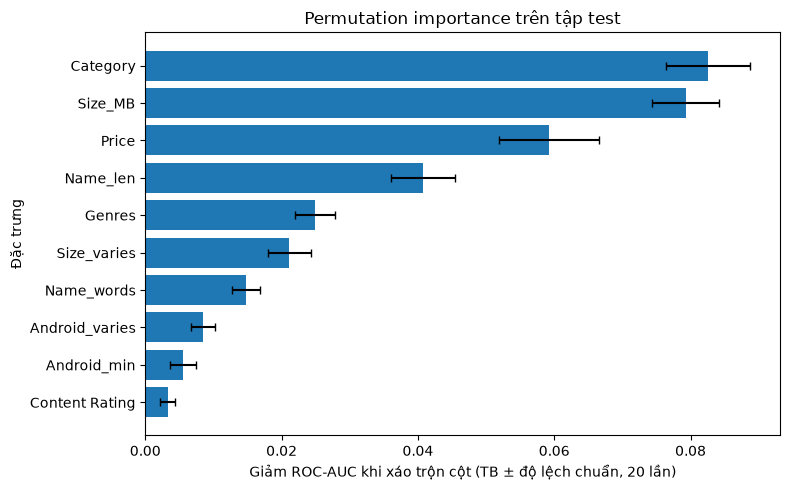

In [9]:
from sklearn.inspection import permutation_importance

best_est = searches[best_name]
perm = permutation_importance(best_est, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=42)
imp = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=X_test.columns).sort_values("mean")
display(imp.sort_values("mean", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp["mean"], xerr=imp["std"], capsize=3)
ax.set(title="Permutation importance trên tập test", xlabel="Giảm ROC-AUC khi xáo trộn cột (TB ± độ lệch chuẩn, 20 lần)", ylabel="Đặc trưng")
plt.tight_layout()
plt.show()

In [10]:
# Đối chứng: mô hình chỉ dùng đặc trưng kỹ thuật (không có Category, Genres, Content Rating, Price).
hgb_params = searches["HistGradientBoosting"].best_params_
tech = make_pipe(HistGradientBoostingClassifier(random_state=42), TECH_COLS, [])
tech.set_params(**hgb_params).fit(X_train[TECH_COLS], y_train)
p_tech = tech.predict_proba(X_test[TECH_COLS])[:, 1]
print(f"Chỉ đặc trưng kỹ thuật: ROC-AUC {roc_auc_score(y_test, p_tech):.4f}, PR-AUC {average_precision_score(y_test, p_tech):.4f}")
print(f"Toàn bộ đặc trưng (HistGradientBoosting): ROC-AUC {test_scores.loc['HistGradientBoosting', 'ROC-AUC']:.4f}, PR-AUC {test_scores.loc['HistGradientBoosting', 'PR-AUC']:.4f}")

Chỉ đặc trưng kỹ thuật: ROC-AUC 0.7708, PR-AUC 0.6846
Toàn bộ đặc trưng (HistGradientBoosting): ROC-AUC 0.8584, PR-AUC 0.7919


- Xếp hạng đóng góp: `Category` (giảm 0,083 ROC-AUC), `Size_MB` (0,079), `Price` (0,059), `Name_len` (0,041), `Genres` (0,025), `Size_varies` (0,021). `Content Rating`, `Android_min` và `Android_varies` gần như không đóng góp (dưới 0,01).
- Nếu chỉ dùng đặc trưng kỹ thuật (kích thước, Android, tên app), ROC-AUC vẫn đạt **0,771**, PR-AUC **0,685**, cao hơn hẳn baseline nhưng thấp hơn mô hình đầy đủ (0,858). Vậy các đặc trưng kỹ thuật đóng góp phần lớn, còn danh mục và giá bổ sung thêm khoảng 0,09 ROC-AUC.
- `Name_len` đóng góp khá lớn, nhưng không nên diễn giải nhân quả: tên ngắn thường là thương hiệu nổi tiếng, nên đây là dấu hiệu của thương hiệu hơn là lựa chọn thiết kế.

#### **7. Trả lời câu hỏi và giới hạn**

**Trả lời:** Chỉ từ thông tin sản phẩm và cấu hình kỹ thuật, mô hình HistGradientBoosting đạt ROC-AUC 0,858, PR-AUC 0,792 và F1 0,717 trên tập test chia theo `App`. Baseline đoán lớp đa số đạt ROC-AUC 0,500, PR-AUC 0,388 và F1 bằng 0, nên mô hình cao hơn 0,358 ROC-AUC và gấp khoảng 2 lần PR-AUC. Quyết định nhất là `Category`, `Size_MB` và `Price`; app miễn phí, thuộc danh mục như `GAME`, dung lượng lớn hoặc "Varies with device" có xác suất đạt triệu lượt tải cao hơn. Phiên bản Android và `Content Rating` gần như không đóng góp.

**Giới hạn:**
- Dữ liệu là ảnh chụp một thời điểm (2018), nên `Size`, tên và `Android Ver` có thể đã thay đổi sau khi ứng dụng có người dùng; "biết trước" chỉ là xấp xỉ.
- Mô hình bỏ sót app phổ biến nhờ thương hiệu hoặc cộng đồng (`Minecraft`, app tôn giáo) và đoán thừa app dung lượng lớn nhưng ít người cài. Dung lượng nhỏ bị mô hình mặc định là không phổ biến (FN 91% ở nhóm <5MB).
- Kết quả là mối liên hệ dự báo, không phải quan hệ nhân quả: tăng dung lượng hoặc đổi tên app không làm tăng lượt cài.
- Ngưỡng 0,5 và ngưỡng 1 triệu là lựa chọn của nhóm; tập test chỉ có 2.066 dòng nên các tỷ lệ lỗi theo danh mục nhỏ chưa ổn định (ví dụ `MEDICAL`).